In [2]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

#  Copyright (c) 2021 - 2022.  FlexibleLecture@Linkedin
#  All rights reserved.

# Created By  : FlexibleLecture@Linkedin
# Created Date: 1/15/2022
# version ='1.0'

# Practice: An Experiment on Solving Linear Programming in Inequality Form by the Barrier Method
In the text book book-convex-2004, section 11.3.2, an example of solving a small linear programming in equality form using the barrier method was discussed:
$$
\begin{array}{rcl}
\text{minimize} & & f_0(x)=c^T x \\
\text{subject to} & & Ax \preceq b \\
\end{array}
$$
where $A\in R^{m\times n}, m > n$. The barrier method is repeated in the following, where the logarithmic barrier function $\phi(x)$ is given by $\phi(x)=-\displaystyle{\sum_{i=1}^m\log(b_i-a_i^Tx)}$.

#### Given the convex optimization problem
$$
\begin{array}{rcl}
\text{minimize} & f_0(x) & \\
\text{subject to} & f_i(x)\leq 0 & i=1,2,...,n\\
& Ax=b & \\
\end{array}
$$
#####  Given strictly feasible $x=x_0$, $t=t^{(0)}>1$, $\mu>1$, and a bound on duality gap $\eta$, repeat: 

1.  Centering step: computing $x^*(t)$ by Newton method in minimizing $tf_0(x)+\phi(x)$ subject to $Ax=b$, starting at $x$

1. Update: $x\leftarrow x^*(t)$

1. If $m/t < \eta$, break

1. Increase $t$: $t\leftarrow \mu t$




In order to achieve an optimal value $p^*=p_{+}$ and a duality gap of $d_{+}$ at the start point $x_0$, the parameters, $A, b, c$ are constructed following the optimality conditions with some scaling: $\exists \lambda, x^*$ to satisfy

\begin{equation}
\begin{array}{rcl}
c+A^T\lambda & = & 0 \\
\lambda & \succeq & 0 \\
Ax^*-b & \preceq & 0 \\
\lambda(Ax^*-b) & = & 0 \\ 
\end{array}
\end{equation}

#### Procedure to generate model parameters, $A, b, c$ with optimal value $p_+>0$, and duality gap $d_+$:

1.  Initialize an optimal point $x^*\in -\mathbf{U}[0,1]^{n}$, let $A\in \mathbf{U}[0, 1]^{m\times n}$, let $\lambda \in \mathbf{U}[0, 1]^{m}$

2. Let $c=-A^T\lambda$. In this way, the optimal value before scaling is $p^*=c^T x^* > 0$

3. Scale $x^*$ by $\beta=p_{+}/p^*$, let $x^* \leftarrow \beta x^*$ so that after scaling $p^*=c^T x^*=p_{+}$

4. Select $x_0=\mathbf{-1}\in R^n$ (which is strictly feasible as $x_0\preceq x^*$, so $Ax_0\preceq Ax^*=b$), and further scale $c, A, x^*$ by $\gamma=(d_{+}+p_{+})/(c^Tx_0)$, i.e., $c\leftarrow \gamma c$, $A\leftarrow \gamma A$, $x^*\leftarrow x^*/\gamma$, so that after scaling, $c^Tx_0=d_++p_+$ (i.e. a duality gap of $d_+$)

5. Let $b=Ax^* + \mathbf{U}[0, \eta]I(\lambda=0)$, where $I$ is the indicator function, and $\eta>0$ is a margin.


In [20]:
import numpy as np
import matplotlib.pyplot as plt

$f_0(x)=c^T x$

$\nabla f_0(x)=c$

$\nabla^2 f_0(x)=0_{n\times n}$

In [4]:
def my_f_0(x, t, A, b, c):
    """
    $f_0(x)=c^T x$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return (c.T @ x).item()


def my_f_0_feasible(x, t, A, b, c):
    return True


def my_gradient_f_0(x, t, A, b, c):
    """
    $\nabla f_0(x)=c$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return c


def my_hessian_f_0(x, t, A, b, c):
    """
    $\nabla^2 f_0(x)=0_{n\times n}$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return np.zeros((len(x), len(x)))

$\phi(x)=-\displaystyle{\sum_{i=1}^{m}}\log(b_i-a_i^Tx)$

$\nabla \phi(x)=A^Td$, where $d=1/(b-Ax)$

$\nabla^2 \phi(x)=A^T\mathbf{diag}(d)^2A$, where $d=1/(b-Ax)$

In [5]:
def my_phi(x, t, A, b, c):
    """
    $\phi(x)=-\displaystyle{\sum_{i=1}^{m}}\log(b_i-a_i^Tx)$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return -1 * np.sum(np.log(b - A @ x))


def my_phi_feasible(x, t, A, b, c):
    """
    To make $\phi(x)$ be feasible, it requires $b\succeq Ax$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return np.all(b - A @ x > 0)


def my_gradient_phi(x, t, A, b, c):
    """
    $\nabla \phi(x)=A^Td$, where $d=1/(b-Ax)$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return A.T @ (1 / (b - A @ x))


def my_hessian_phi(x, t, A, b, c):
    """
    $\nabla^2 \phi(x)=A^T\textbf{diag}(d)^2A$, where $d=1/(b-Ax)$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return A.T @ np.diag(np.squeeze(1 / ((b - A @ x) ** 2))) @ A

$f(x)=tf_0(x)+\phi(x)$

$\nabla f(x)=t\nabla f_0(x)+\nabla \phi(x)$

$\nabla^2 f(x)=t\nabla^2 f_0(x)+\nabla^2 \phi(x)$

In [6]:
def my_f(x, t, A, b, c):
    """
    $f(x)=tf_0(x)+\phi(x)$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return t * my_f_0(x, t, A, b, c) + my_phi(x, t, A, b, c)


def my_f_feasible(x, t, A, b, c):
    return my_f_0_feasible(x, t, A, b, c) and my_phi_feasible(x, t, A, b, c)


def my_gradient_f(x, t, A, b, c):
    """
    $\nabla f(x)=t\nabla f_0(x)+\nabla \phi(x)$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return t * my_gradient_f_0(x, t, A, b, c) + my_gradient_phi(x, t, A, b, c)


def my_hessian_f(x, t, A, b, c):
    """
    $\nabla^2 f(x)=t\nabla^2 f_0(x)+\nabla^2 \phi(x)$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return t * my_hessian_f_0(x, t, A, b, c) + my_hessian_phi(x, t, A, b, c)

Calculation of the Newton step: $\Delta x_{nt}=-\nabla^2f(x)^{-1}\nabla f(x)$

In [7]:
def my_newton_step_decrement(x, args):
    """
    Calculation of the Newton step: $\Delta x_{nt}=-\nabla^2f(x)^{-1}\nabla f(x)$
    :param x:
    :param args:
    :return:
    """
    gradient = my_gradient_f(x, *args)
    hessian = my_hessian_f(x, *args)
    hessian_inv = np.linalg.inv(hessian)
    x_nt = -1 * hessian_inv @ gradient
    decrement = -1 * gradient.T @ x_nt
    return x_nt, decrement.item()

Backtracking line search implementation, see to Algorithm 9.2 in the textbook

In [8]:
def backtracking_line_search(f, df, x, delta_x, alpha, beta, args):
    """
    Backtracking line search implementation, see to Algorithm 9.2 in the textbook
    :param f:
    :param df:
    :param x:
    :param delta_x:
    :param alpha:
    :param beta:
    :param args:
    :return:
    """
    t = 1
    while (not my_f_feasible(x + delta_x * t, *args)) \
            or f(x + delta_x * t, *args) > f(x, *args) + alpha * t * ((df(x, *args).T @ delta_x).item()):
        t = beta * t
    return t

Generate model parameter, A, b, c with optimal point xp, start point x0 with optimal value equal to p ($p_+$), and
     duality gap equal to duality_gap ($d_+$).

Refer to Algorithm-2 in the FlexibleLecture note

In [9]:
def get_A_b(m, n, p, nI, duality_gap):
    """
    Generate model parameter, A, b, c with optimal point xp, start point x0 with optimal value equal to p ($p_+$), and
     duality gap equal to duality_gap ($d_+$)
    Refer to Algorithm-2 in the FlexibleLecture note
    :param m:
    :param n:
    :param p:
    :param nI: $\mathcal{I}$, the number of inequality constraints activation, i.e. $|I[Ax^*=b]|_1=|\lambda\neq 0|$
    :param duality_gap:
    :return:
    """
    if nI > m or nI < 0:
        raise RuntimeError('nI should be equal to or less than m, and greater than zero.')

    x_asterisk_init = -np.random.rand(n, 1)
    A = np.random.rand(m, n)
    b = np.zeros((m, 1))

    # In the experiment, set $\lambda [0: (m - nI)]=0, \lambda [m - nI:]>0$
    lambda_ = np.random.rand(m, 1)
    if m - nI > 0:
        lambda_[0:m - nI, 0] = 0

    c = -A.T @ lambda_
    x0 = -1 * np.ones((n, 1))

    f_min = my_f_0(x_asterisk_init, None, None, None, c)
    if not f_min > 0:
        raise RuntimeError('it is preferred to have optimal value > 0 for experiment.')

    # to scale the parameters so that the primal value = p
    beta = p / f_min
    xp = x_asterisk_init * beta

    f_min = my_f_0(xp, None, None, None, c)
    # print('fmin={}, p ={}'.format(f_min, p))

    # to rescale C, A, xp so that the dual gap at the x0 is dual_gap
    f_x0 = c.T @ x0
    gamma = (duality_gap + p) / f_x0
    c = gamma * c
    A = gamma * A
    xp = xp / gamma

    Ax = A @ xp
    eta = 1
    for i, lambda_i in enumerate(lambda_):
        if lambda_i > 0:
            b[i] = Ax[i]
        else:
            b[i] = Ax[i] + np.random.rand(1, 1) * eta

    # print('f(x0)={}'.format(c.T @ x0))

    if not (np.linalg.matrix_rank(A) == min(m, n)):
        raise RuntimeError('A is not full rank?')

    if not np.allclose(A @ xp, b) and not (np.all(A @ xp <= b)):
        raise RuntimeError('problem is not feasible? A @ x <=b')

    if not np.all(A @ x0 <= b):
        raise RuntimeError('start point should be feasible at Ax <= b')

    if not (np.allclose(c + A.T @ lambda_, 0)):
        raise RuntimeError('problem is not feasible? c + A.T @ lambda == 0')

    if not (np.allclose(lambda_.T @ (A @ xp - b), 0)):
        raise RuntimeError('problem is not feasible? lambda.T @ (A @ x - b) == 0')

    if not np.allclose(f_min - p, 0):
        raise RuntimeError('It is required to have f_min = p')

    if not np.allclose(my_f_0(x0, None, A, b, c) - p, duality_gap):
        raise RuntimeError('It is required to have a duality gap = {}'.format(duality_gap))

    return A, b, c, xp, x0

The centering step, to compute $x^*(t)$ by minimizing $tf_0+\phi$, starting from x0, with the parameters,
    $\alpha$, $\beta$ in the backtracking line search method.
    

In [10]:
def centering_step(x0, epsilon, alpha, beta, barrier_t, A, b, c):
    """
    The centering step, to compute $x^*(t)$ by minimizing $tf_0+\phi$, starting from x0, with the parameters,
    $\alpha$, $\beta$ in the backtracking line search method.
    :param x0:
    :param epsilon:
    :param alpha:
    :param beta:
    :param barrier_t: t
    :param A:
    :param b:
    :param c:
    :return:
    """
    x = x0
    args = (barrier_t, A, b, c)
    x_nt, decrement = my_newton_step_decrement(x, args)

    fx = []
    tx = []
    decrements = []
    fx.append(my_f(x, *args))
    decrements.append(decrement)

    iteration = 0
    while decrement / 2 > epsilon:
        # print(r'Info: t={}, iteration={}, decrement={}'.format(barrier_t, iteration, decrement))
        t = backtracking_line_search(my_f, my_gradient_f, x, x_nt, alpha, beta, args)
        tx.append(t)

        x_next = x + t * x_nt
        x = x_next
        x_nt, decrement = my_newton_step_decrement(x, args)

        fx.append(my_f(x, *args))
        decrements.append(decrement)
        iteration = iteration + 1

        # When number of iteration is too large (here larger than 1000),
        # it means the center step does not converge, then break directly.
        if iteration > 1000:
            print('Warning: the centering step does not converged after 1000 Newton iterations.')
            break

    # print(r'Info: t={}, iteration={}, decrement={}'.format(barrier_t, iteration, decrement))
    n_iter = iteration
    xt = x
    return xt, n_iter, fx, decrement, tx

Plot the convergence diagram for different $\mathcal{I}\in$ nI_s

In [11]:
def plot_barrier_method_convergence(m, n, nI_s, seed):
    """
    plot the convergence diagram for different $\mathcal{I}\in$ nI_s
    :param m: 
    :param n: 
    :param nI_s: 
    :param seed: 
    :return: 
    """
    markers = ["o", "v", "s", "d", "p", ">", "<"]
    if m < n:
        raise RuntimeError('it requires m > n')

    if len(nI_s) > len(markers):
        raise RuntimeError('Error: only support number of elements in nI_s less than {}'.format(len(nI_s)))

    plt.figure(figsize=(16, 8))

    for z_i, nI in enumerate(nI_s):
        np.random.seed(seed)
        ax = plt.subplot(len(nI_s), 1, z_i + 1)
        p = 1  # expected optimal value
        duality_gap = 100  # duality gap at the start point
        A, b, c, xp, x0 = get_A_b(m, n, p, nI, duality_gap)

        alpha = 0.01
        beta = 0.5
        epsilon = 1e-5  # the threshold of Newton decrement where Newton iteration stops
        duality_gap_epsilon = 1e-6

        mu_s = [2, 8, 32, 128, 512, 1024, 2048]  # $\mu $

        for mu_i, mu in enumerate(mu_s):
            t0 = 10
            t = t0

            n_iterations = []
            f0 = []
            xt = x0.copy()

            n_iterations.append(0)
            accumulate_iteration = 0
            f0.append(my_f_0(x0, None, A, b, c))
            while True:
                args = (t, A, b, c)
                xt_next, n_iter, fx, decrement, tx = centering_step(xt, epsilon, alpha, beta, *args)
                # print('Info: centering step completed at t={}, num. iterations={}, f0={}'.format(
                #    t, n_iter, my_f_0(xt_next, *args)))
                accumulate_iteration = accumulate_iteration + n_iter

                n_iterations.append(accumulate_iteration)
                f0.append(my_f_0(xt, *args))
                n_iterations.append(accumulate_iteration)
                f0.append(my_f_0(xt_next, *args))

                xt = xt_next
                if m / t < duality_gap_epsilon:
                    break
                else:
                    t = mu * t

            # print('Info: Final optimal point difference = |$x^*$ - xp|={}, final optimal value={}'.format(
            #    np.linalg.norm(xt_next - xp), my_f_0(xt_next, None, A, b, c)))

            ax.semilogy(n_iterations, np.array(f0) - p, linestyle='dashed', fillstyle='none', marker=markers[mu_i],
                        label=r'$\mu$={}'.format(mu))
        ax.set_xlim(0, 100)
        ax.set_ylim(duality_gap_epsilon / 10, 200)
        ax.set_ylabel(r'f(x)')
        if z_i == len(nI_s) - 1:
            ax.set_xlabel('iteration')
        if z_i == 0:
            ax.legend()
            ax.set_title('f(x) vs. iteration, m={},n={},$|I[Ax_p=b]|_1$={}'.format(m, n, nI))
        else:
            ax.set_title('$|I[Ax_p=b]|_1$={}'.format(nI))

        ax.grid()

    plt.show()

 Plot a figure similar to Figure 11.5 in the textbook, 
 comparing the average of the number of Newton iterations for different $\mu$

In [12]:
def plot_barrier_method_iterations_vs_mu(m, n, n_dials):
    """
    Plot a figure similar to Figure 11.5 in the textbook, 
    comparing the average of the number of Newton iterations for different $\mu$
    :param m:
    :param n:
    :param n_dials:
    :return:
    """
    if m < n:
        raise RuntimeError('Error: it requires m > n')

    plt.figure(figsize=(12, 8))

    mu_s_list = [np.linspace(1.1, 5, num=40, endpoint=True), np.linspace(5, 200, num=165, endpoint=True)]
    major_ticks_list = [np.linspace(1, 5, num=5, endpoint=True), np.linspace(5, 195, num=20, endpoint=True)]
    minor_ticks_list = mu_s_list

    for set_i, mu_s in enumerate(mu_s_list):
        ax = plt.subplot(len(mu_s_list), 1, set_i + 1)
        n_iterations = np.zeros((n_dials, len(mu_s)))

        for dial_i, dial in enumerate(range(n_dials)):
            np.random.seed(dial)

            nI = m
            p = 1
            duality_gap = 100
            A, b, c, xp, x0 = get_A_b(m, n, p, nI, duality_gap)

            alpha = 0.01
            beta = 0.5
            epsilon = 1e-5
            duality_gap_epsilon = 1e-3

            for mu_i, mu in enumerate(mu_s):
                t0 = 1
                t = t0

                xt = x0.copy()
                accumulate_iteration = 0
                while True:
                    args = (t, A, b, c)
                    xt_next, n_iter, fx, decrement, tx = centering_step(xt, epsilon, alpha, beta, *args)
                    # print('Info: centering step completed at t={}, num. iterations={}, f0={}'.format(
                    #    t, n_iter, my_f_0(xt_next, *args)))
                    accumulate_iteration = accumulate_iteration + n_iter

                    xt = xt_next
                    if m / t < duality_gap_epsilon:
                        break
                    else:
                        t = mu * t

                # print('Info: Final optimal point difference = |$x^*$ - xp|={}, final optimal value={}'.format(
                #    np.linalg.norm(xt_next - xp), my_f_0(xt_next, None, A, b, c)))
                n_iterations[dial_i][mu_i] = accumulate_iteration

        avg_iterations = np.average(n_iterations, axis=0)
        std_iterations = np.std(n_iterations, axis=0)
        ax.errorbar(mu_s, avg_iterations, yerr=std_iterations * 1, linestyle='dotted', marker='o', fillstyle='none',
                    uplims=False, lolims=False, label=r'mean $\pm 1\sigma$')
        ax.set_xticks(major_ticks_list[set_i])
        ax.set_xticks(minor_ticks_list[set_i], minor=True)

        ax.grid(which='both')
        ax.set_xlabel(r'$\mu$')
        ax.set_ylabel('#iteration')
        ax.legend()
    plt.show()

In [13]:
import ipywidgets as widgets
from IPython.display import display

In [17]:
wid_dropdown = widgets.Dropdown(
    options=[('[m-n]', 0), ('[m, m - int(m / 4), m - int(m / 2), m - int(3 * m / 4), 1]', 1)],
    value=0,
    description='nI = ',
)
output = widgets.Output()
display(wid_dropdown, output)

Dropdown(description='nI = ', options=(('[m-n]', 0), ('[m, m - int(m / 4), m - int(m / 2), m - int(3 * m / 4),…

Output()

nI = [10, 8, 5, 3, 1]


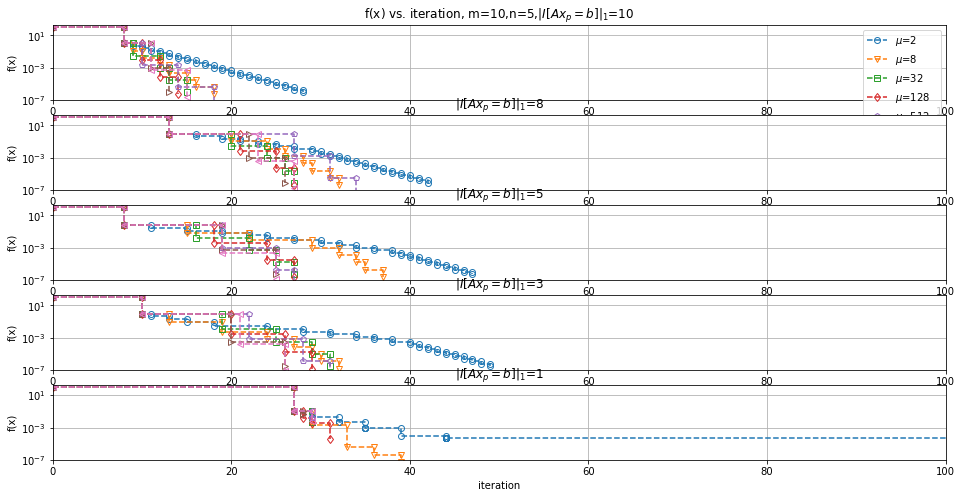

In [19]:
if __name__ == "__main__":
    m = 10
    n = 5
    seed = 1
    nI_s = [m-n] 
    if wid_dropdown.value == 0:
        nI_s = [m-n]
    elif wid_dropdown.value == 1:
        nI_s = [m, m - int(m / 4), m - int(m / 2), m - int(3 * m / 4), 1]
    print('nI = {}'.format(nI_s))    
    plot_barrier_method_convergence(m, n, nI_s, seed)

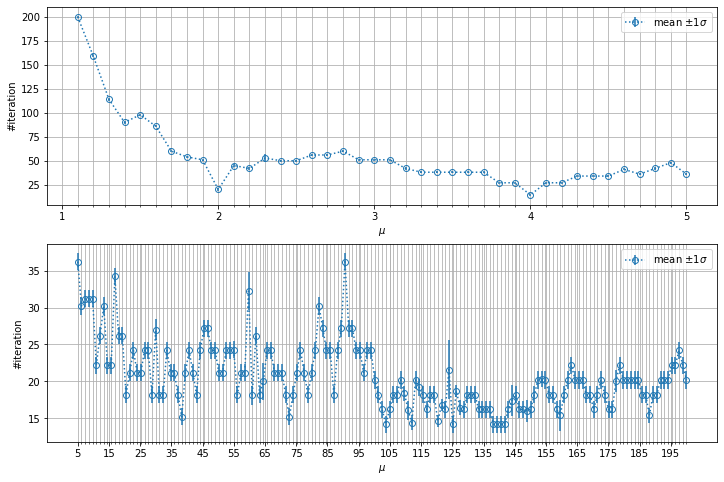

In [16]:
if __name__ == "__main__":
    m = 10
    n = 5
    n_dials = 10
    plot_barrier_method_iterations_vs_mu(m, n, n_dials)